# 30 Support Vector Machine (SVM) Programs for Data Science
A comprehensive hands-on guide covering SVM classifications, regressions, kernel tricks, hyperparameter tuning, imbalance handling, and real-world pipelines using `scikit-learn`.


### 1. Binary Classification with Linear SVC

In [1]:
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=100, centers=2, random_state=42)
clf = SVC(kernel='linear')
clf.fit(X, y)

print("Support Vectors Count:", len(clf.support_vectors_))
print("Model Accuracy:", clf.score(X, y))

Support Vectors Count: 2
Model Accuracy: 1.0


### 2. Soft Margin Classification (Tuning C Parameter)

In [2]:
from sklearn.datasets import make_classification
from sklearn.svm import SVC

X, y = make_classification(n_samples=100, n_features=2, n_redundant=0, random_state=42)

for c_val in [0.01, 1.0, 100.0]:
    clf = SVC(kernel='linear', C=c_val).fit(X, y)
    print(f"C={c_val} | Support Vectors: {len(clf.support_vectors_)} | Score: {clf.score(X, y):.2f}")

C=0.01 | Support Vectors: 76 | Score: 0.95
C=1.0 | Support Vectors: 13 | Score: 0.99
C=100.0 | Support Vectors: 5 | Score: 0.99


### 3. Decision Boundary Visualization

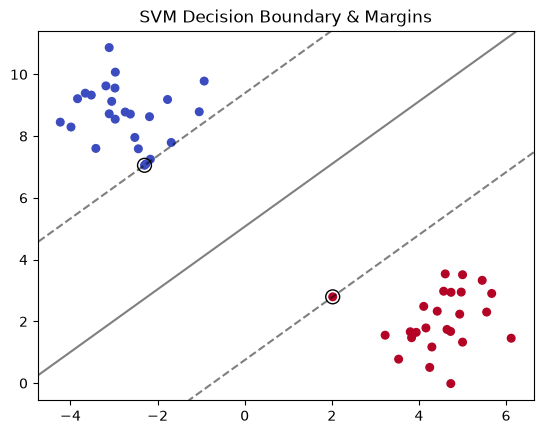

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=50, centers=2, random_state=42)
clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=30)
ax = plt.gca()
xlim, ylim = ax.get_xlim(), ax.get_ylim()

xx, yy = np.meshgrid(np.linspace(xlim[0], xlim[1], 30), np.linspace(ylim[0], ylim[1], 30))
Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

ax.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=100, linewidth=1, facecolors='none', edgecolors='k')
plt.title("SVM Decision Boundary & Margins")
plt.show()

### 4. Non-linear Classification with RBF Kernel

In [4]:
from sklearn.datasets import make_circles
from sklearn.svm import SVC

X, y = make_circles(n_samples=200, noise=0.1, factor=0.5, random_state=42)
clf = SVC(kernel='rbf', gamma='scale').fit(X, y)

print("RBF Kernel Training Accuracy:", clf.score(X, y))

RBF Kernel Training Accuracy: 0.995


### 5. Polynomial Kernel Classification

In [5]:
from sklearn.datasets import make_moons
from sklearn.svm import SVC

X, y = make_moons(n_samples=200, noise=0.15, random_state=42)
clf = SVC(kernel='poly', degree=3, C=5).fit(X, y)

print("Polynomial Kernel Score:", clf.score(X, y))

Polynomial Kernel Score: 0.92


### 6. Sigmoid Kernel Classification

In [6]:
from sklearn.datasets import make_classification
from sklearn.svm import SVC

X, y = make_classification(n_samples=150, n_features=4, random_state=42)
clf = SVC(kernel='sigmoid', C=1.0).fit(X, y)

print("Sigmoid Kernel Accuracy:", clf.score(X, y))

Sigmoid Kernel Accuracy: 0.86


### 7. Impact of Gamma Hyperparameter in RBF Kernel

In [7]:
from sklearn.datasets import make_moons
from sklearn.svm import SVC

X, y = make_moons(n_samples=100, noise=0.2, random_state=42)

for g in [0.1, 1, 10]:
    clf = SVC(kernel='rbf', gamma=g).fit(X, y)
    print(f"Gamma={g} | Support Vectors: {len(clf.support_vectors_)} | Score: {clf.score(X, y):.2f}")

Gamma=0.1 | Support Vectors: 52 | Score: 0.86
Gamma=1 | Support Vectors: 35 | Score: 0.94
Gamma=10 | Support Vectors: 59 | Score: 0.97


### 8. Fast Linear Classification with LinearSVC

In [8]:
from sklearn.datasets import make_classification
from sklearn.svm import LinearSVC

X, y = make_classification(n_samples=1000, n_features=10, random_state=42)
clf = LinearSVC(max_iter=2000, dual=False).fit(X, y)

print("LinearSVC Accuracy:", clf.score(X, y))

LinearSVC Accuracy: 0.862


### 9. Multi-class Classification (One-vs-Rest)

In [9]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

X, y = load_iris(return_X_y=True)
clf = OneVsRestClassifier(SVC(kernel='rbf')).fit(X, y)

print("OvR Multi-class Accuracy:", clf.score(X, y))

OvR Multi-class Accuracy: 0.9533333333333334


### 10. Multi-class Classification (One-vs-One)

In [10]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.multiclass import OneVsOneClassifier

X, y = load_iris(return_X_y=True)
clf = OneVsOneClassifier(SVC(kernel='rbf')).fit(X, y)

print("OvO Multi-class Accuracy:", clf.score(X, y))

OvO Multi-class Accuracy: 0.9733333333333334


### 11. Importance of Feature Scaling in SVM

In [11]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Unscaled
clf_unscaled = SVC().fit(X_train, y_train)
print("Unscaled Accuracy:", clf_unscaled.score(X_test, y_test))

# Scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf_scaled = SVC().fit(X_train_scaled, y_train)
print("Scaled Accuracy:", clf_scaled.score(X_test_scaled, y_test))

Unscaled Accuracy: 0.935672514619883
Scaled Accuracy: 0.9766081871345029


### 12. Extracting & Visualizing Feature Importances with Linear SVM

In [12]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

data = load_breast_cancer()
X_scaled = StandardScaler().fit_transform(data.data)

clf = SVC(kernel='linear').fit(X_scaled, data.target)
importance = pd.Series(clf.coef_[0], index=data.feature_names).sort_values()

print("Top 3 Positive Features:\n", importance.tail(3))
print("\nTop 3 Negative Features:\n", importance.head(3))

Top 3 Positive Features:
 compactness error          0.391154
mean compactness           0.619259
fractal dimension error    0.885835
dtype: float64

Top 3 Negative Features:
 worst concavity       -1.038189
worst texture         -0.971904
mean concave points   -0.909685
dtype: float64


### 13. Predicting Probability Estimates with SVM

In [13]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC

X, y = load_iris(return_X_y=True)
clf = SVC(kernel='rbf', probability=True).fit(X, y)

probs = clf.predict_proba(X[:3])
print("Predicted Class Probabilities:\n", probs)

Predicted Class Probabilities:
 [[0.97758737 0.0143319  0.00808073]
 [0.96950006 0.02140375 0.00909618]
 [0.97869242 0.01344695 0.00786064]]


/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### 14. Cross-Validation Evaluation

In [14]:
from sklearn.datasets import load_digits
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
pipeline = make_pipeline(StandardScaler(), SVC(kernel='rbf'))

scores = cross_val_score(pipeline, X, y, cv=5)
print("5-Fold Cross Validation Accuracy:", scores.mean())

5-Fold Cross Validation Accuracy: 0.9460229031259673


### 15. Hyperparameter Tuning using GridSearchCV

In [15]:
from sklearn.datasets import load_wine
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

X, y = load_wine(return_X_y=True)

pipe = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])
param_grid = {
    'svm__C': [0.1, 1, 10],
    'svm__gamma': ['scale', 'auto', 0.01, 0.1],
    'svm__kernel': ['rbf', 'poly']
}

grid = GridSearchCV(pipe, param_grid, cv=3).fit(X, y)
print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Best Parameters: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV Score: 0.9887005649717514


### 16. Randomized Search for SVM Tuning

In [16]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from scipy.stats import loguniform

X, y = load_breast_cancer(return_X_y=True)

pipe = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])
param_distributions = {
    'svm__C': loguniform(1e-2, 1e2),
    'svm__gamma': loguniform(1e-4, 1e0),
    'svm__kernel': ['rbf']
}

search = RandomizedSearchCV(pipe, param_distributions, n_iter=10, cv=3, random_state=42).fit(X, y)
print("Best Params:", search.best_params_)

Best Params: {'svm__C': np.float64(8.471801418819979), 'svm__gamma': np.float64(0.024810409748678097), 'svm__kernel': 'rbf'}


### 17. Handling Imbalanced Datasets using class_weight

In [17]:
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.metrics import classification_report

X, y = make_classification(n_samples=1000, weights=[0.9, 0.1], random_state=42)

# Unweighted
clf_standard = SVC().fit(X, y)
print("Standard SVM Report:\n", classification_report(y, clf_standard.predict(X)))

# Weighted
clf_balanced = SVC(class_weight='balanced').fit(X, y)
print("Balanced SVM Report:\n", classification_report(y, clf_balanced.predict(X)))

Standard SVM Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.98       897
           1       0.93      0.66      0.77       103

    accuracy                           0.96      1000
   macro avg       0.95      0.83      0.88      1000
weighted avg       0.96      0.96      0.96      1000

Balanced SVM Report:
               precision    recall  f1-score   support

           0       1.00      0.96      0.98       897
           1       0.75      0.98      0.85       103

    accuracy                           0.96      1000
   macro avg       0.88      0.97      0.92      1000
weighted avg       0.97      0.96      0.97      1000



### 18. Custom Sample Weights in Fitting

In [18]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=100, centers=2, random_state=42)
weights = np.ones(len(y))
weights[y == 1] = 5.0  # Give 5x weight to positive samples

clf = SVC().fit(X, y, sample_weight=weights)
print("Weighted Fit Completed. Support vectors count:", len(clf.support_vectors_))

Weighted Fit Completed. Support vectors count: 6


### 19. Building Scikit-Learn Pipelines with SVM

In [19]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=5)),
    ('svm', SVC(kernel='rbf', C=1.0))
])

pipeline.fit(X_train, y_train)
print("Pipeline Test Accuracy:", pipeline.score(X_test, y_test))

Pipeline Test Accuracy: 0.9649122807017544


### 20. Support Vector Regression (SVR) Basics

In [20]:
import numpy as np
from sklearn.svm import SVR

X = np.sort(5 * np.random.rand(40, 1), axis=0)
y = np.sin(X).ravel()

svr = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1).fit(X, y)
y_pred = svr.predict(X)

print("SVR Prediction Score (R^2):", svr.score(X, y))

SVR Prediction Score (R^2): 0.9920664896407172


### 21. Linear SVR for High-Dimensional Regression

In [21]:
from sklearn.datasets import make_regression
from sklearn.svm import LinearSVR

X, y = make_regression(n_samples=500, n_features=20, noise=0.2, random_state=42)
svr = LinearSVR(max_iter=2000, random_state=42).fit(X, y)

print("LinearSVR Score (R^2):", svr.score(X, y))

LinearSVR Score (R^2): 0.9999974391950129


### 22. Impact of Epsilon Parameter in SVR

In [22]:
import numpy as np
from sklearn.svm import SVR

X = np.linspace(0, 5, 50).reshape(-1, 1)
y = X.ravel() + np.random.normal(0, 0.2, 50)

for eps in [0.01, 0.5, 1.0]:
    svr = SVR(epsilon=eps).fit(X, y)
    print(f"Epsilon={eps} | Support Vectors: {len(svr.support_vectors_)}")

Epsilon=0.01 | Support Vectors: 50
Epsilon=0.5 | Support Vectors: 6
Epsilon=1.0 | Support Vectors: 4


### 23. One-Class SVM for Novelty/Anomaly Detection

In [23]:
import numpy as np
from sklearn.svm import OneClassSVM

X = 0.3 * np.random.randn(100, 2)
X_train = np.r_[X + 2, X - 2]

# Outliers
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))

clf = OneClassSVM(nu=0.1, kernel="rbf", gamma=0.1).fit(X_train)

y_pred_train = clf.predict(X_train)
y_pred_outliers = clf.predict(X_outliers)

print("Detected Inliers in Training Data:", np.sum(y_pred_train == 1))
print("Detected Outliers in Anomaly Set:", np.sum(y_pred_outliers == -1))

Detected Inliers in Training Data: 179
Detected Outliers in Anomaly Set: 20


### 24. Text Classification using TF-IDF and LinearSVC

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline

corpus = [
    'This movie is fantastic and amazing',
    'Terrible film, hated it completely',
    'Great acting and wonderful story',
    'Worst experience, bad directing'
]
labels = [1, 0, 1, 0]

model = make_pipeline(TfidfVectorizer(), LinearSVC())
model.fit(corpus, labels)

print("Prediction:", model.predict(["Awesome performance and great plot"]))

Prediction: [1]


### 25. Image Classification with SVM (Handwritten Digits)

In [25]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

clf = SVC(kernel='rbf', C=5, gamma=0.01).fit(X_train, y_train)
print("Digits Test Accuracy:", clf.score(X_test, y_test))

Digits Test Accuracy: 0.9833333333333333


### 26. Custom Kernel Matrix with Precomputed Kernel

In [26]:
import numpy as np
from sklearn.svm import SVC

X = np.array([[0, 0], [1, 1], [2, 2], [3, 3]])
y = np.array([0, 0, 1, 1])

# Compute Linear Kernel Gram Matrix
gram_matrix = np.dot(X, X.T)

clf = SVC(kernel='precomputed').fit(gram_matrix, y)
print("Precomputed Kernel Score:", clf.score(gram_matrix, y))

Precomputed Kernel Score: 1.0


### 27. Cumulative Explained Variance Reduction with PCA + SVM

In [27]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

X, y = load_breast_cancer(return_X_y=True)

X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=0.95)  # Retain 95% variance
X_pca = pca.fit_transform(X_scaled)

clf = SVC().fit(X_pca, y)
print(f"Reduced features from {X.shape[1]} to {X_pca.shape[1]}")
print("PCA + SVM Accuracy:", clf.score(X_pca, y))

Reduced features from 30 to 10
PCA + SVM Accuracy: 0.984182776801406


### 28. Calibrated Classifier CV (Probability Calibration)

In [28]:
from sklearn.datasets import make_classification
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

X, y = make_classification(n_samples=500, n_features=5, random_state=42)

base_svm = LinearSVC(dual=False)
calibrated_svm = CalibratedClassifierCV(estimator=base_svm, cv=3).fit(X, y)

probs = calibrated_svm.predict_proba(X[:2])
print("Calibrated Probabilities:\n", probs)

Calibrated Probabilities:
 [[0.0959133  0.9040867 ]
 [0.88088623 0.11911377]]


### 29. Generating Evaluation Curves (Precision-Recall)

In [29]:
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.metrics import precision_recall_curve, average_precision_score

X, y = make_classification(n_samples=300, random_state=42)
clf = SVC(kernel='rbf', probability=True).fit(X, y)

y_scores = clf.decision_function(X)
precision, recall, _ = precision_recall_curve(y, y_scores)
ap_score = average_precision_score(y, y_scores)

print(f"Average Precision (AP) Score: {ap_score:.3f}")

Average Precision (AP) Score: 0.990


/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### 30. Exporting and Loading SVM Model with Joblib

In [30]:
import joblib
from sklearn.datasets import load_iris
from sklearn.svm import SVC

X, y = load_iris(return_X_y=True)
clf = SVC().fit(X, y)

# Save model
joblib.dump(clf, 'svm_model.pkl')

# Load model
loaded_clf = joblib.load('svm_model.pkl')
print("Loaded Model Score:", loaded_clf.score(X, y))

Loaded Model Score: 0.9733333333333334
